# 02 · EX-1 (One-to-One) · RE3 · TS2Vec

**Skema EX-1:** dataset sumber S = RE3. Alurnya: pre-training SSL di S, lalu fine-tuning di S, lalu evaluasi di S. Ini adalah **baseline in-domain**.

Komputasi dijalankan oleh `scripts/run_ex1.py`. Notebook ini menjelaskan metodenya lalu membaca hasil dari `results/ex1/RE3_ts2vec/`.

```
python scripts/run_ex1.py --source RE3 --model ts2vec --seeds 0 1 2 --n-iters 600 --fineall-epochs 30
```

## 1. Metode

### 1.1 Data
Preprocessing sama dengan `01_preprocessing_baseline.ipynb`: K = 5 kanal per service, robust z-score pra-injeksi, dan split 60/20/20 terstratifikasi (seed 42). Ukuran split dicetak di sel kode di bawah.

- **Input encoder per service** = 5 kanal metrik + 5 kanal mask (konstan sepanjang waktu), sehingga `input_dims = 10`. Mask disertakan supaya encoder bisa membedakan "kanal tidak ada" dari "kanal normal (z ≈ 0)".
- **Data pre-training (tanpa label):** seluruh rekaman kasus split **train**, dipotong per service menjadi window 540 detik dengan stride 270. Kasus val/test tidak pernah dilihat saat pre-training.

### 1.2 TS2Vec (Yue et al., 2022)
Hyperparameter mengikuti default kode resmi: hidden 64, output 320, 10 blok, batch 16, lr 1e-3, 600 iterasi, AdamW.

- **Encoder:** proyeksi linear, lalu *timestamp masking* (Bernoulli p = 0.5 saat training), lalu dilated CNN 10 blok residual (dilasi 2^l). Keluarannya representasi 320 dimensi **per timestamp**.
- **Augmentasi contextual consistency:** dua *random crop* yang overlap diambil dari window yang sama. Representasi pada timestamp yang sama di bagian overlap harus mirip.
- **Hierarchical contrastive loss:** pada setiap skala waktu (representasi di-*max-pool* ×2 berulang kali), dua loss digabung:
  - *instance-wise*: sampel lain di batch pada timestamp yang sama dianggap negatif;
  - *temporal*: timestamp lain di sampel yang sama dianggap negatif.
- Encoder akhir adalah rata-rata bobot sepanjang training (SWA), sama seperti kode resmi.

### 1.3 Fine-tuning: lokalisasi root service
Untuk setiap service *i* dalam satu kasus:

$$h_i = \mathrm{Enc}(x_i) \in \mathbb{R}^{T\times 320},\quad f_i = [\,\max_{t\ge t_{inj}} h_{i,t}\ ;\ \max_{t\ge t_{inj}} h_{i,t} - \max_{t< t_{inj}} h_{i,t}\,] \in \mathbb{R}^{640}$$

$$s_i = \mathrm{MLP}(f_i),\qquad p(\text{root}=i) = \mathrm{softmax}_i(s_1,\dots,s_N)$$

Loss yang dipakai adalah cross-entropy terhadap root service. Encoder dan head dipakai bersama untuk semua service, sehingga model tidak bergantung pada jumlah service (ob 11, ss 15, tt 64). Ini penting untuk transfer di EX-2.

| Mode | Yang dilatih | Detail |
|---|---|---|
| **FineLast** | head saja (encoder dibekukan) | AdamW lr 1e-3, ≤200 epoch, early stopping (patience 30) |
| **FineAll** | encoder + head | lr encoder 1e-4, head 1e-3, ≤30 epoch, patience 8; batch efektif 4 kasus (gradient accumulation) |

Model terbaik dipilih berdasarkan **loss validasi**, lalu dievaluasi **sekali** di test.

### 1.4 Pembanding
- **Heuristik:** ranking service berdasarkan rata-rata |z| pasca-injeksi (notebook 01), tanpa pembelajaran.
- **Scratch (kontrol):** encoder TS2Vec **acak tanpa pre-training**, dengan FineLast/FineAll yang sama persis. Selisih *pretrain − scratch* adalah kontribusi SSL yang sebenarnya.

Semua varian dijalankan dengan **3 seed** (0, 1, 2). Seed memengaruhi pre-training, inisialisasi, dan urutan batch. Split-nya tetap sama.

**Metrik:** AC@k (root service ada di k teratas) dan Avg@5 = rata-rata AC@1..AC@5.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from ssl_rcl.finetune import summarize_ranks

R = ROOT / "results" / "ex1" / "RE3_ts2vec"
summary = pd.read_csv(R / "summary.csv")
pred = pd.read_csv(R / "predictions.csv")
hist = pd.read_csv(R / "history.csv")
ptl = pd.read_csv(R / "pretrain_loss.csv")
heur = pd.read_csv(R / "heuristic_test.csv")
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
print(open(R / "config.json").read())
print("ukuran test:", heur.shape[0], "kasus | per sistem:", heur.system.value_counts().to_dict())

{
  "source": "RE3",
  "model": "ts2vec",
  "seeds": [
    0,
    1,
    2
  ],
  "n_iters": 600,
  "pt_window": 540,
  "pt_stride": 270,
  "fineall_epochs": 30,
  "no_scratch": false,
  "device": "mps",
  "pretrain_device": "cpu"
}
ukuran test: 18 kasus | per sistem: {'ss': 7, 'tt': 6, 'ob': 5}


## 2. Pre-training: kurva loss

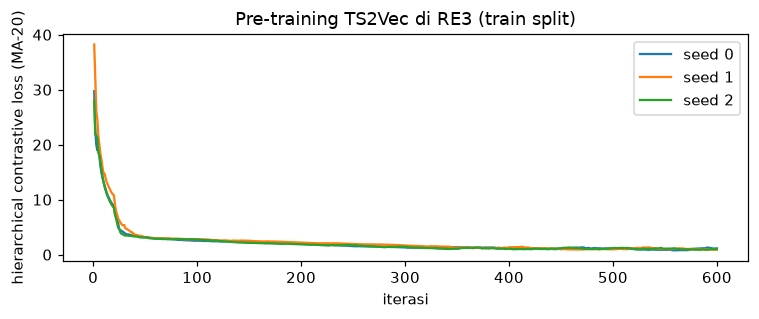

In [2]:
fig, ax = plt.subplots(figsize=(7, 3))
for s, g in ptl.groupby("seed"):
    ax.plot(g["iter"], g["loss"].rolling(20, min_periods=1).mean(), label=f"seed {s}")
ax.set_xlabel("iterasi"); ax.set_ylabel("hierarchical contrastive loss (MA-20)"); ax.legend(); ax.set_title("Pre-training TS2Vec di RE3 (train split)")
plt.tight_layout()

## 3. Hasil utama di split test

In [3]:
metrics = ["AC@1", "AC@3", "AC@5", "Avg@5"]
agg = summary.groupby(["variant", "mode"])[metrics].agg(["mean", "std"])
tbl = pd.DataFrame({m: agg[(m, "mean")].map("{:.3f}".format) + " ± " + agg[(m, "std")].map("{:.3f}".format) for m in metrics})
h = summarize_ranks(heur["rank"])
tbl.loc[("heuristic", "-"), :] = [f"{h[m]:.3f}" for m in metrics]
tbl

AC@1           AC@3           AC@5          Avg@5
variant   mode                                                                
pretrain  FineAll   1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000
          FineLast  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000
scratch   FineAll   1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000
          FineLast  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000
heuristic -                 0.667          0.944          1.000          0.900

/var/folders/dh/c1dp0bj54rjb_jfvb0t3llw80000gn/T/ipykernel_2597/2580679867.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  v = summary.set_index(["variant", "mode"]).loc[key, "AC@1"]
/var/folders/dh/c1dp0bj54rjb_jfvb0t3llw80000gn/T/ipykernel_2597/2580679867.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  v = summary.set_index(["variant", "mode"]).loc[key, "AC@1"]
/var/folders/dh/c1dp0bj54rjb_jfvb0t3llw80000gn/T/ipykernel_2597/2580679867.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  v = summary.set_index(["variant", "mode"]).loc[key, "AC@1"]
/var/folders/dh/c1dp0bj54rjb_jfvb0t3llw80000gn/T/ipykernel_2597/2580679867.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  v = summary.set_index(["variant", "mode"]).loc[key, "AC@1"]


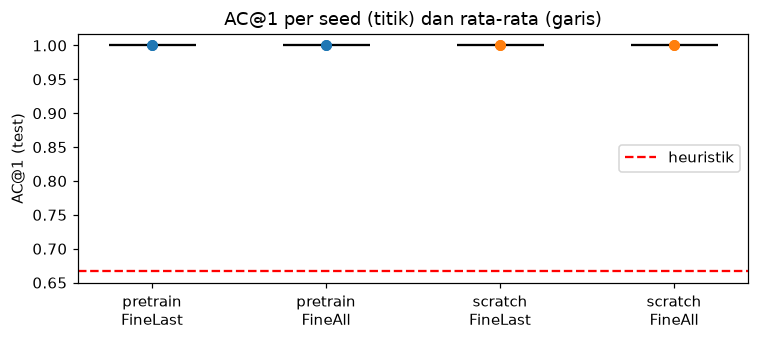

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
order = [("pretrain", "FineLast"), ("pretrain", "FineAll"), ("scratch", "FineLast"), ("scratch", "FineAll")]
for j, key in enumerate(order):
    v = summary.set_index(["variant", "mode"]).loc[key, "AC@1"]
    ax.scatter([j] * len(v), v, color="C0" if key[0] == "pretrain" else "C1", zorder=3)
    ax.hlines(np.mean(v), j - .25, j + .25, color="k")
ax.axhline(h["AC@1"], color="red", ls="--", label="heuristik")
ax.set_xticks(range(len(order)), [f"{a}\n{b}" for a, b in order]); ax.set_ylabel("AC@1 (test)")
ax.set_title("AC@1 per seed (titik) dan rata-rata (garis)"); ax.legend(); plt.tight_layout()

## 4. Rincian per sistem dan per jenis fault
Nilai di bawah adalah AC@1, dirata-rata atas seed. Jumlah kasus test per sistem kecil (lihat sel pertama), jadi selisih kecil bisa jadi hanya 1 kasus.

In [5]:
def ac1_by(col):
    m = pred.groupby(["variant", "mode", "seed", col])["rank"].apply(lambda r: (r <= 1).mean()) \
            .groupby(["variant", "mode", col]).mean().unstack(col)
    hh = heur.groupby(col)["rank"].apply(lambda r: (r <= 1).mean()).rename(("heuristic", "-")).to_frame().T
    hh.index = pd.MultiIndex.from_tuples(hh.index, names=["variant", "mode"])
    return pd.concat([m, hh]).round(3)

display(ac1_by("system"))
display(ac1_by("fault"))

system               ob     ss     tt
variant   mode                       
pretrain  FineAll   1.0  1.000  1.000
          FineLast  1.0  1.000  1.000
scratch   FineAll   1.0  1.000  1.000
          FineLast  1.0  1.000  1.000
heuristic -         1.0  0.714  0.333

fault                f1   f2     f3   f4   f5
variant   mode                               
pretrain  FineAll   1.0  1.0  1.000  1.0  1.0
          FineLast  1.0  1.0  1.000  1.0  1.0
scratch   FineAll   1.0  1.0  1.000  1.0  1.0
          FineLast  1.0  1.0  1.000  1.0  1.0
heuristic -         0.5  0.5  0.667  1.0  1.0

## 5. Kasus yang paling sulit
Kasus test di mana model **pretrain-FineAll** (rata-rata seed) atau heuristik **tidak** menempatkan root service di urutan pertama.

In [6]:
best = pred[(pred.variant == "pretrain") & (pred["mode"] == "FineAll")].groupby("name")["rank"].mean().rename("rank_pretrain_FineAll")
scr = pred[(pred.variant == "scratch") & (pred["mode"] == "FineAll")].groupby("name")["rank"].mean().rename("rank_scratch_FineAll")
cmp = heur.set_index("name")[["system", "fault", "rank"]].rename(columns={"rank": "rank_heuristik"}).join(best).join(scr)
cmp[(cmp.rank_heuristik > 1) | (cmp.rank_pretrain_FineAll > 1)].sort_values(["system", "fault"])

,system,fault,rank_heuristik,rank_pretrain_FineAll,rank_scratch_FineAll
name,,,,,
re3ss_front-end_f1_1,ss,f1,2,1.0,1.0
re3ss_front-end_f3_2,ss,f3,2,1.0,1.0
re3tt_ts-auth-service_f1_1,tt,f1,4,1.0,1.0
re3tt_ts-auth-service_f1_2,tt,f1,3,1.0,1.0
re3tt_ts-route-service_f2_2,tt,f2,2,1.0,1.0
re3tt_ts-route-service_f2_3,tt,f2,2,1.0,1.0


## 6. Kurva validasi fine-tuning

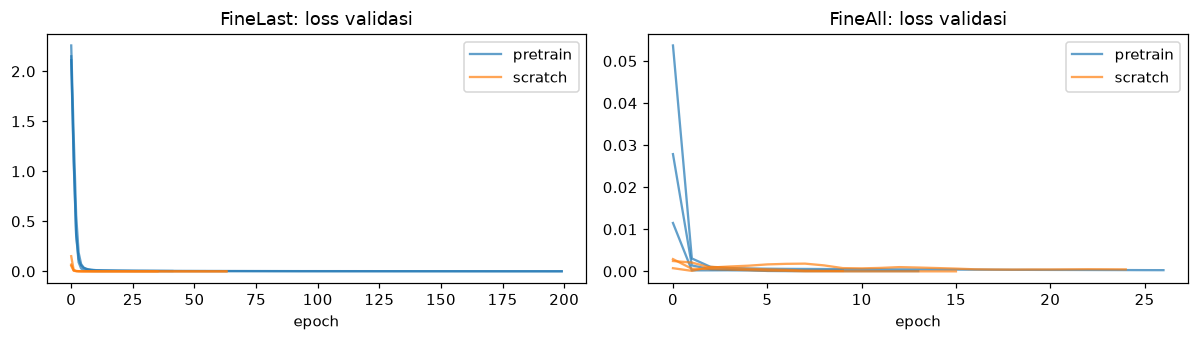

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, mode in zip(axes, ["FineLast", "FineAll"]):
    for (v, s), g in hist[hist["mode"] == mode].groupby(["variant", "seed"]):
        ax.plot(g["epoch"], g["val_loss"], color="C0" if v == "pretrain" else "C1", alpha=.7,
                label=v if s == 0 else None)
    ax.set_title(f"{mode}: loss validasi"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout()

## 7. Kesimpulan

1. **Semua varian sempurna (AC@1 = 1.000 untuk 3 seed), sedangkan heuristik hanya 0.667.** Di RE3, besarnya penyimpangan saja tidak cukup (fault level kode f1–f5), tetapi pola yang dipelajari model cukup untuk membedakan root service.

2. **Hasil ini bukan kebocoran label.** Uji di `03_ex1_ringkasan.ipynb` menunjukkan bahwa jika anomali dihapus dari data test, AC@1 model jatuh ke 0.00. Jadi model memang memakai anomali, bukan sekadar mengenali service yang sering menjadi root.

3. **Namun, RE3 in-domain tidak bisa membedakan pretrain vs scratch.**
   - Split test hanya **18 kasus** (5–7 per sistem).
   - Root service hanya 2–4 per sistem; di tt hanya 2 dari 68 service. Tanpa data pun, prior frekuensi sudah mencapai AC@1 0.5 dan AC@3 1.0.
   - Semua varian mencapai ceiling.

4. **Implikasi:** RE3 lebih berguna sebagai **target** di EX-2 (transfer dari RE1/RE2 dengan data berlabel sangat sedikit) daripada sebagai benchmark in-domain. Jika dipakai di laporan, sebaiknya disertai evaluasi yang lebih stabil, misalnya k-fold cross-validation, karena 18 kasus test terlalu sedikit.

5. Catatan: FineLast pretrain seed 1 dan 2 berjalan sampai batas 200 epoch, karena loss validasi terus turun mendekati 0. Ini tanda tugasnya sudah terpisahkan dengan sempurna.